# Pregunta 2: Porcentaje de Fraude vs. Legítimas y Monto Promedio por Sucursal

**Equipo:** Lavanderia de Datos (ITESO - Programación para el Análisis de Datos)  
**Pregunta base (Entrega 1):**
> ¿Cuál es el porcentaje total de las transacciones fraudulentas vs legítimas, cuál es el monto promedio por sucursal?

**Tablas relacionadas (ver `docs/relaciones_tablas.md`):**
- `transactions_data.csv` (`id`, `amount`, `merchant_id`, `merchant_city`, `merchant_state`, `mcc`, `date`)
- `train_fraud_labels.json` (`transaction_id`, etiqueta de fraude)
- `mcc_codes.json` (`mcc_id`, `mcc_nombre`) *(opcional para contextualizar giros comerciales)*

**Regla de documentación del equipo:**
Por cada cambio que hagan en el código o módulo que añadan, escriban un comentario para entender qué es lo que hace su código / función, por qué decidieron implementar esta solución, etc.

## 1. Carga de librerías y datos procesados

In [27]:
# Por cada cambio que hagan en el código o módulo que añadan, escriban un comentario
# para entender qué es lo que hace su código / función, por qué decidieron implementar
# esta solución, etc.
#
# Espacio para importar librerías y cargar transacciones + etiquetas de fraude
# desde `data/procesamiento_data/` (o desde `data/raw_data/` / SQLite).

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

transcations_data = pd.read_csv('../../data/procesamiento_data/transcations_data.csv')
transcations_data.set_index('id',inplace=True)
display(transcations_data.head())

,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,card_type,card_brand,purchase_category,is_fraud
id,,,,,,,,,,,,,,,
7475327,2010-01-01 00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,NaN,Debit (Prepaid),Mastercard,Miscellaneous Food Stores,False
7475328,2010-01-01 00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,NaN,Credit,Mastercard,Department Stores,False
7475329,2010-01-01 00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.0,4829,NaN,Debit,Mastercard,Money Transfer,False
7475331,2010-01-01 00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.0,4829,NaN,Debit,Mastercard,Money Transfer,False
7475332,2010-01-01 00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.0,5813,NaN,Debit,Visa,Drinking Places (Alcoholic Beverages),False


## 2. Porcentaje total de transacciones fraudulentas vs. legítimas

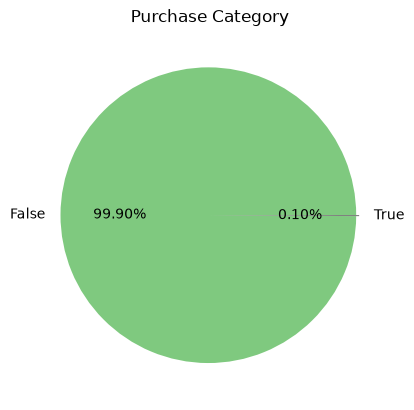

The fraud percent is: 10.02%


In [ ]:
# Por cada cambio que hagan en el código o módulo que añadan, escriban un comentario
# para entender qué es lo que hace su código / función, por qué decidieron implementar
# esta solución, etc.
#
# Espacio para calcular conteos, porcentajes de transacciones fraudulentas frente a
# legítimas y generar sus gráficas correspondientes.

# Pie chart para enseñar el porcentaje de fraude
size = [.01 for i in range(len(transcations_data['is_fraud'].unique()))]
transcations_data.groupby('is_fraud').size().plot(kind='pie',explode=size,autopct='%.02f%%',cmap='Accent')
plt.title('Purchase Category')
plt.axis('off')
plt.show()

# Enseñar el porcentaje de fraude con texto
full = len(transcations_data)
fraud = len(transcations_data[transcations_data['is_fraud']==True])
print("The fraud percent is:",f'{fraud*100/full:.2%}')

## 3. Monto promedio por sucursal / comercio

In [52]:
# Por cada cambio que hagan en el código o módulo que añadan, escriban un comentario
# para entender qué es lo que hace su código / función, por qué decidieron implementar
# esta solución, etc.
#
# Espacio para definir cómo agrupar las sucursales/comercios (`merchant_id`, ciudad,
# estado), calcular el monto promedio (general y separado por fraude/legítima) y graficar.

# Crear un subset de transcations_data para calcular monto promedio por comercio
# Excluir transacciones fraudulentas y quedarse solo con las columnas necesarias
subset = transcations_data[transcations_data["is_fraud"] == False]
subset = subset[["amount", "purchase_category"]]

# Eliminar compras menores a $1 para evitar que distorsionen los promedios
subset = subset[subset["amount"] >= 1]

# Crear columna auxiliar para contabilizar cada fila como 1 compra y sumar por categoría
subset["number_purchases"] = 1
df = subset.groupby(["purchase_category"]).sum()

# Calcular el ticket promedio por categoría
df["average_amount_spent"] = df["amount"] / df["number_purchases"]

# Calcular qué porcentaje representa cada categoría sobre el gasto total
total_amount = df["amount"].sum()
df["percent"] = df["amount"].map(lambda x: x * 100 / total_amount)

# Ordenar de mayor a menor según la cantidad de compras y mostrar el top 5
df.sort_values(by="number_purchases", ascending=False, inplace=True)
display(df.head())

,amount,number_purchases,average_amount_spent,percent
purchase_category,,,,
"Grocery Stores, Supermarkets",40932487.63,1554996,26.323211,6.419801
Service Stations,51226009.02,1123691,45.587274,8.034224
Miscellaneous Food Stores,37264425.79,1033175,36.067874,5.844506
Eating Places and Restaurants,26332512.91,980979,26.843095,4.129959
Drug Stores and Pharmacies,35079467.69,765008,45.855034,5.501820


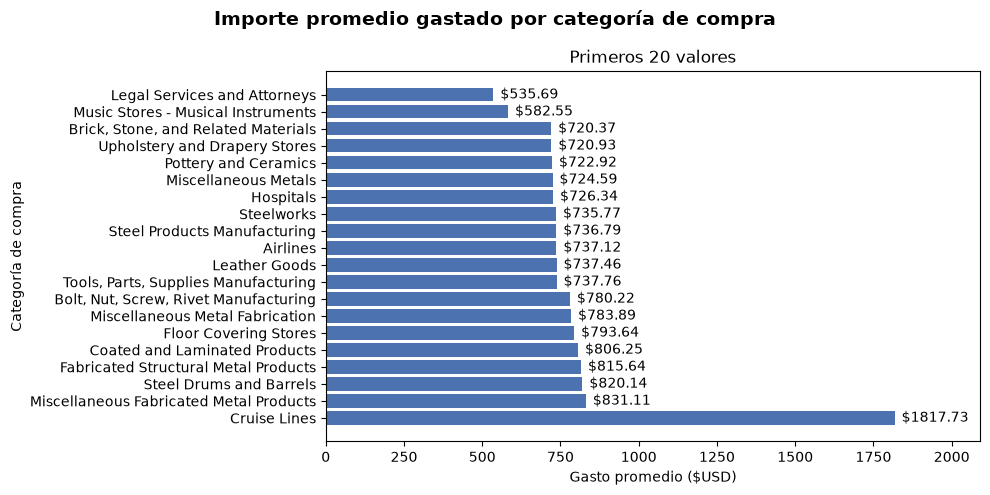

In [53]:
# Crear nuevo dataframe que contenga los primeors 20 valores mas grandes de gastos
df_sorted = df.sort_values('average_amount_spent', ascending=False)[:20]

# Crea el gráfico de barras horizontales utilizando df_sorted.index para las categorías.
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(df_sorted.index, df_sorted['average_amount_spent'], color='#4C72B0')

# Añadir etiquetas con el valor exacto al final de cada barra
ax.bar_label(bars, fmt='$%.2f', padding=5)

# Agreagar las etiquetas, el título y el espaciado de los ejes
ax.set_xlabel('Gasto promedio ($USD)')
ax.set_ylabel('Categoría de compra')
fig.suptitle("Importe promedio gastado por categoría de compra", fontsize=14, fontweight="bold")
ax.set_title('Primeros 20 valores')
ax.set_xlim(0, df_sorted['average_amount_spent'].max() * 1.15)  # Extra room for labels

# Enseñar grafico
plt.tight_layout()
plt.show()

## 4. Conclusiones y respuesta a la Pregunta 2

Documenten aquí los porcentajes obtenidos, el comportamiento del monto promedio por sucursal y las interpretaciones de negocio.